# Despliegue de la solución: de la PD a la prima
## Modelo de riesgo de default crediticio · Lending Club
**Ciencia de Datos Aplicada · ITBA · Cuarto entregable**

Gianluca Giannine Lizarraga · Timoteo Harrington · Lucas Kim

**Qué hace este notebook.** En la Entrega 03 guardamos un modelo que ordena bien el riesgo, pero cuya PD queda un punto por debajo del default real, y una pérdida esperada con una severidad única de 51,7%. Acá terminamos el sistema que usa la API:

1. **Calibramos la PD** con un ajuste de intercepto estimado en validación, como sugirió la devolución de E03.
2. **Estimamos una severidad por banda**, porque los préstamos más riesgosos pierden más.
3. **Calculamos la prima** (PD calibrada × severidad de la banda) y la comparamos con la pérdida real en test.
4. **Definimos la regla de decisión** (aprobar, revisar o rechazar) y medimos qué logra frente al criterio de Lending Club.
5. **Calculamos los valores típicos** con los que la API completa los datos del buró que no vienen en la solicitud.
6. **Guardamos todo** en `modelos/modelo_pd.json`. El modelo (`modelo_pd.joblib`) no se vuelve a entrenar.

**Contenido**
1. Datos y modelo guardado
2. PD de validación
3. Calibración de la PD
4. Severidad por banda
5. Prima y pérdida esperada en test
6. Regla de decisión
7. Valores típicos para completar la solicitud
8. Guardar los parámetros y probar el evaluador
9. Conclusiones

In [1]:
import sys, json
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.metrics import roc_auc_score

from src import modelado as M
from src import evaluacion as E
from src import pricing as P
from src.solicitud import BURO
from src.graficos import aplicar_estilo, guardar, AZUL, NARANJA, AQUA, GRIS

aplicar_estilo()
pd.set_option('display.width', 160)
pct = mtick.PercentFormatter(1.0, decimals=0)

## 1. Datos y modelo guardado

Usamos los mismos `train` y `test` que generó el notebook 02 y el modelo final de la Entrega 03, tal como quedó guardado.

In [2]:
train = pd.read_parquet('../data/train.parquet')
test = pd.read_parquet('../data/test.parquet')
modelo, meta = M.cargar_modelo()
y_train, y_test = train['default'], test['default']

CORTES, BANDAS = meta['bandas']['cortes_pd'], meta['bandas']['nombres']
SEVERIDAD_UNICA = meta['severidad_sobre_monto']
pd_test = M.predecir_pd(modelo, test)

print(f"Train: {len(train):,} préstamos | Test: {len(test):,} préstamos")
print(f"Test con el modelo guardado: AUC {roc_auc_score(y_test, pd_test):.4f} "
      f"(E03: {meta['metricas_test']['roc_auc']:.4f}), PD media {pd_test.mean():.2%}, default {y_test.mean():.2%}")

Train: 511,150 préstamos | Test: 107,195 préstamos
Test con el modelo guardado: AUC 0.7044 (E03: 0.7044), PD media 13.85%, default 14.83%


## 2. PD de validación

Para estimar la calibración y la severidad por banda necesitamos PD de préstamos que el modelo no vio al entrenar, **sin usar test**. Repetimos los tres cortes por año de la Entrega 03 (2013, 2014 y enero a agosto de 2015) con la misma configuración de LightGBM, sin desempleo. Son las mismas PD con las que se definieron los cortes de las bandas: lo verificamos abajo.

In [3]:
ANIOS = [2013, 2014, 2015]
pd_validacion = pd.Series(np.nan, index=train.index)
for anio, i_apr, i_val in M.cortes_temporales(train['fecha_originacion'], ANIOS):
    m = M.crear_modelo('lightgbm', meta['hiperparametros'], con_macro=False)
    m.fit(train.iloc[i_apr], y_train.iloc[i_apr])
    pd_validacion.iloc[i_val] = M.predecir_pd(m, train.iloc[i_val])

val = train.loc[pd_validacion.notna()].copy()
val['pd'] = pd_validacion.dropna()
val['anio'] = val['fecha_originacion'].dt.year

# Los cortes de las bandas salen de estas PD (E03, Sección 7): deben coincidir
proporcion = val['grade'].value_counts(normalize=True).sort_index().cumsum().iloc[:-1]
cortes_recalculados = val['pd'].quantile(proporcion.values).to_numpy()
print('Diferencia máxima con los cortes guardados:', f"{np.abs(cortes_recalculados - CORTES).max():.2e}")

val.groupby('anio').apply(lambda g: pd.Series({
    'préstamos': len(g), 'AUC': roc_auc_score(g['default'], g['pd']),
    'PD media': g['pd'].mean(), 'default observado': g['default'].mean()}), include_groups=False).style.format(
    {'préstamos': '{:,.0f}', 'AUC': '{:.4f}', 'PD media': '{:.2%}', 'default observado': '{:.2%}'})

Diferencia máxima con los cortes guardados: 0.00e+00


,préstamos,AUC,PD media,default observado
anio,,,,
2013,"100,422",0.6717,12.47%,12.33%
2014,"162,570",0.6845,13.10%,13.73%
2015,"175,592",0.6946,13.79%,14.92%


**Qué vemos.** Los cortes de las bandas salen idénticos a los guardados, así que estas son las mismas PD de validación de la Entrega 03. En 2013 la PD media casi coincide con el default (12,5% contra 12,3%), pero la brecha crece año a año: en 2014 falta 0,6 puntos y en enero a agosto de 2015, 1,1 puntos. El default venía subiendo y el modelo, que aprende del promedio, va un paso atrás.

## 3. Calibración de la PD

**Qué corregimos.** El modelo ordena bien, pero su nivel queda corto: el default venía subiendo y el modelo aprende del promedio de todo el período. En los tres años de validación también pasa, y la brecha es mayor en el último.

**Cómo.** Con un **ajuste de intercepto**: sumamos una constante $b$ a las log-odds de cada PD,

$$PD_{calibrada} = \frac{1}{1 + e^{-(\text{logit}(PD) + b)}}$$

y elegimos $b$ para que la PD promedio iguale al default observado. Sube el nivel sin cambiar el orden (el AUC no cambia) y la PD nunca pasa de 100%.

**Con qué datos.** Con el último año de validación (enero a agosto de 2015), que es el más parecido a test. Como control, también lo estimamos con los tres años juntos.

In [4]:
ultimo = val[val['anio'] == 2015]
INTERCEPTO = P.estimar_intercepto(ultimo['pd'], ultimo['default'])
intercepto_tres_anios = P.estimar_intercepto(val['pd'], val['default'])
print(f"Intercepto con ene-ago 2015: {INTERCEPTO:+.4f}  (factor de odds {np.exp(INTERCEPTO):.3f})")
print(f"Intercepto con 2013-2015:    {intercepto_tres_anios:+.4f}  (solo como control)")

pd_test_cal = P.calibrar_pd(pd_test, INTERCEPTO)
antes = E.metricas_pd(y_test, pd_test)
despues = E.metricas_pd(y_test, pd_test_cal)
comparacion = pd.DataFrame({'E03, sin calibrar': antes, 'E04, calibrada': despues}).T
comparacion['brecha (pp)'] = (comparacion['default_observado'] - comparacion['pd_media']) * 100
comparacion.style.format({'roc_auc': '{:.4f}', 'pr_auc': '{:.4f}', 'ks': '{:.4f}', 'brier': '{:.5f}',
                          'pd_media': '{:.2%}', 'default_observado': '{:.2%}', 'brecha (pp)': '{:+.2f}'})

Intercepto con ene-ago 2015: +0.0978  (factor de odds 1.103)
Intercepto con 2013-2015:    +0.0589  (solo como control)


,roc_auc,pr_auc,ks,brier,pd_media,default_observado,brecha (pp)
"E03, sin calibrar",0.7044,0.2865,0.2966,0.11772,13.85%,14.83%,+0.98
"E04, calibrada",0.7044,0.2865,0.2966,0.11756,14.98%,14.83%,-0.15


**Qué vemos.**
- El intercepto es **+0,098**: multiplica las odds de default por 1,10. Una PD de 10% pasa a 10,9% y una de 30%, a 32,1%.
- En test, la brecha entre la PD media y el default real pasa de **+0,98 puntos a −0,15**: la PD calibrada promedio (15,0%) queda muy cerca del 14,8% real, apenas por encima.
- El **AUC, el KS y el PR-AUC no cambian**, porque el orden es el mismo. El Brier mejora un poco (de 0,11772 a 0,11756).
- Con los tres años de validación juntos, el intercepto sería +0,059 y corregiría menos. Usamos el último año porque es el más parecido a test: el default venía subiendo.

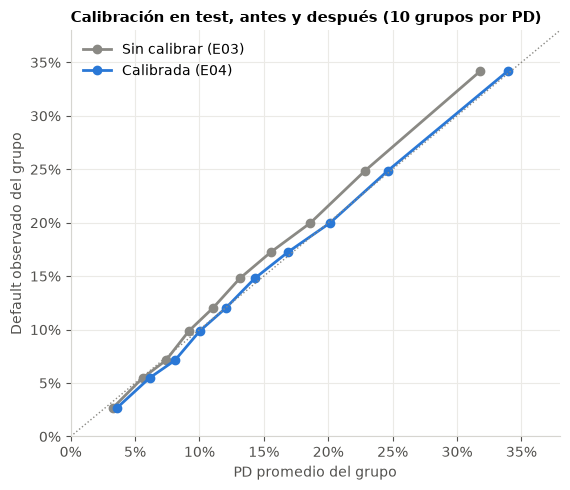

In [5]:
fig, ax = plt.subplots(figsize=(5.8, 5))
for nombre, p, color in [('Sin calibrar (E03)', pd_test, GRIS), ('Calibrada (E04)', pd_test_cal, AZUL)]:
    cal = E.tabla_calibracion(y_test, p)
    ax.plot(cal['pd_media'], cal['default_observado'], marker='o', color=color, label=nombre)
limite = 0.38
ax.plot([0, limite], [0, limite], color=GRIS, linestyle=':', linewidth=1)
ax.set_xlim(0, limite); ax.set_ylim(0, limite)
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set_xlabel('PD promedio del grupo'); ax.set_ylabel('Default observado del grupo')
ax.set_title('Calibración en test, antes y después (10 grupos por PD)')
ax.legend(loc='upper left')
ax.grid(axis='x')
plt.tight_layout()
guardar(fig, '21_calibracion_e04')
plt.show()

En el gráfico, los puntos grises (E03) quedaban por encima de la diagonal desde el grupo de 9% de PD en adelante: el modelo predecía menos default del que hubo. Los azules (calibrados) quedan sobre la diagonal en casi todo el recorrido.

## 4. Severidad por banda

**Qué corregimos.** En la Entrega 03 usamos una severidad única: si hay default, se pierde el 51,7% del monto. Pero en test la pérdida esperada quedaba corta en las bandas altas, porque los préstamos más riesgosos dejan de pagar antes, cuando todavía deben más.

**Cómo.** Asignamos la banda a cada préstamo de validación (con su PD de validación y los cortes de E03) y calculamos la pérdida promedio de los defaults de cada banda, como % del monto prestado. Es la misma unidad que la severidad única. Usamos validación (2013 a agosto de 2015) y no test.

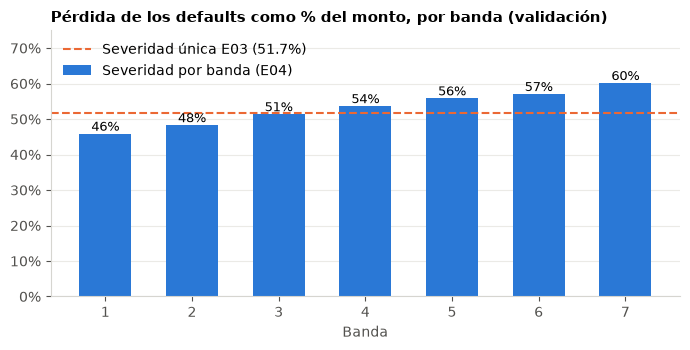

,defaults,severidad,severidad única (E03)
banda,,,
1,"4,431",45.9%,51.7%
2,"15,117",48.3%,51.7%
3,"20,304",51.4%,51.7%
4,"14,014",53.7%,51.7%
5,"5,476",55.9%,51.7%
6,"1,363",57.1%,51.7%
7,179,60.2%,51.7%


In [6]:
val['banda'] = P.asignar_banda(val['pd'], CORTES, BANDAS)
defaults_val = val[val['default'] == 1]
severidad = defaults_val.groupby('banda')['perdida_sobre_monto'].agg(defaults='size', severidad='mean').reindex(BANDAS)
severidad['severidad única (E03)'] = SEVERIDAD_UNICA
SEVERIDAD_POR_BANDA = {b: float(s) for b, s in severidad['severidad'].items()}

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(BANDAS, severidad['severidad'], color=AZUL, width=0.6, label='Severidad por banda (E04)')
ax.axhline(SEVERIDAD_UNICA, color=NARANJA, linestyle='--', linewidth=1.5, label=f'Severidad única E03 ({SEVERIDAD_UNICA:.1%})')
for i, v in enumerate(severidad['severidad']):
    ax.text(i, v + 0.008, f'{v:.0%}', ha='center', fontsize=9)
ax.set_ylim(0, 0.75); ax.yaxis.set_major_formatter(pct)
ax.set_xlabel('Banda'); ax.set_title('Pérdida de los defaults como % del monto, por banda (validación)')
ax.legend(loc='upper left')
plt.tight_layout()
guardar(fig, '22_severidad_por_banda')
plt.show()
severidad.style.format({'defaults': '{:,.0f}', 'severidad': '{:.1%}', 'severidad única (E03)': '{:.1%}'})

**Qué vemos.** La severidad sube de forma pareja con el riesgo: de **45,9% en la banda 1 a 60,2% en la 7**. La severidad única de 51,7% sobrestimaba la pérdida de los préstamos seguros y subestimaba la de los riesgosos. La banda 7 tiene pocos defaults en validación (179), así que su severidad es la menos precisa, pero sigue la misma tendencia.

## 5. Prima y pérdida esperada en test

La **prima** de cada préstamo es su PD calibrada por la severidad de su banda: la pérdida esperada de toda la vida del préstamo, como % del monto. Ahora sí la comparamos con lo que pasó en test, junto con la versión de la Entrega 03 (PD sin calibrar × 51,7%).

La **cobertura** es pérdida esperada / pérdida observada: 100% significa que la prima cubre exactamente lo que se perdió.

In [7]:
banda_test = P.asignar_banda(pd_test, CORTES, BANDAS)
prima_test = P.calcular_prima(pd_test_cal, P.severidad_de_banda(banda_test, SEVERIDAD_POR_BANDA))
prima_e03 = pd_test * SEVERIDAD_UNICA
perdida_test = test['perdida_sobre_monto'].fillna(0).where(y_test == 1, 0)

t = pd.DataFrame({'banda': banda_test, 'default': y_test.values, 'pd_cal': pd_test_cal,
                  'prima_e04': prima_test, 'prima_e03': prima_e03, 'perdida': perdida_test.values})
por_banda = t.groupby('banda').agg(prestamos=('default', 'size'), default_observado=('default', 'mean'),
                                   pd_calibrada=('pd_cal', 'mean'), perdida_observada=('perdida', 'mean'),
                                   prima_e03=('prima_e03', 'mean'), prima_e04=('prima_e04', 'mean')).reindex(BANDAS)
por_banda.loc['Total'] = [len(t), t['default'].mean(), t['pd_cal'].mean(), t['perdida'].mean(),
                          t['prima_e03'].mean(), t['prima_e04'].mean()]
por_banda['cobertura E03'] = por_banda['prima_e03'] / por_banda['perdida_observada']
por_banda['cobertura E04'] = por_banda['prima_e04'] / por_banda['perdida_observada']
por_banda.style.format({'prestamos': '{:,.0f}', 'default_observado': '{:.1%}', 'pd_calibrada': '{:.1%}',
                        'perdida_observada': '{:.1%}', 'prima_e03': '{:.1%}', 'prima_e04': '{:.1%}',
                        'cobertura E03': '{:.0%}', 'cobertura E04': '{:.0%}'})

,prestamos,default_observado,pd_calibrada,perdida_observada,prima_e03,prima_e04,cobertura E03,cobertura E04
banda,,,,,,,,
1,"22,645",4.2%,5.0%,2.0%,2.4%,2.3%,121%,117%
2,"33,933",10.2%,10.5%,5.0%,5.0%,5.1%,100%,102%
3,"28,610",17.6%,17.4%,9.2%,8.3%,8.9%,90%,97%
4,"15,467",25.9%,25.8%,14.1%,12.4%,13.9%,88%,98%
5,"5,257",35.2%,34.9%,20.1%,16.9%,19.5%,84%,97%
6,"1,154",45.8%,43.9%,26.8%,21.5%,25.1%,80%,94%
7,129,57.4%,54.9%,33.9%,27.1%,33.0%,80%,97%
Total,"107,195",14.8%,15.0%,7.8%,7.2%,7.7%,92%,99%


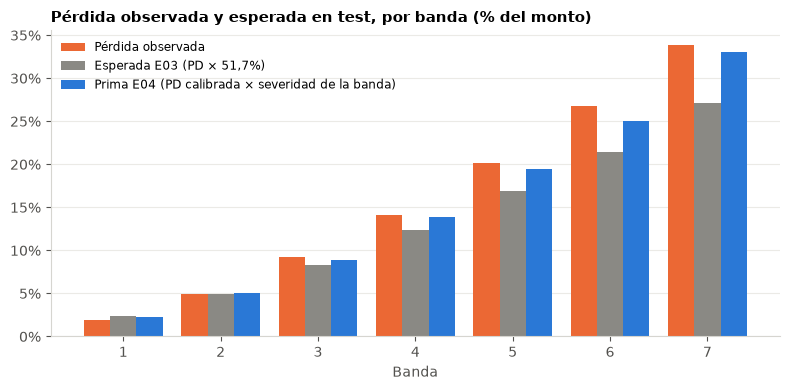

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(BANDAS))
datos = por_banda.loc[BANDAS]
ax.bar(x - 0.27, datos['perdida_observada'], width=0.27, color=NARANJA, label='Pérdida observada')
ax.bar(x, datos['prima_e03'], width=0.27, color=GRIS, label='Esperada E03 (PD × 51,7%)')
ax.bar(x + 0.27, datos['prima_e04'], width=0.27, color=AZUL, label='Prima E04 (PD calibrada × severidad de la banda)')
ax.set_xticks(x, BANDAS); ax.set_xlabel('Banda')
ax.yaxis.set_major_formatter(pct)
ax.set_title('Pérdida observada y esperada en test, por banda (% del monto)')
ax.legend(loc='upper left', fontsize=8.5)
plt.tight_layout()
guardar(fig, '23_prima_vs_perdida')
plt.show()

**Qué vemos.**
- En total, la prima cubre el **99% de la pérdida real** de test (7,7% contra 7,8% del monto). La versión de E03 cubría el 92%.
- Por banda, la cobertura de E04 queda entre 94% y 117%. En E03 iba de 121% en la banda 1 a 80% en las bandas 6 y 7: cobraba de más a los seguros y de menos a los riesgosos.
- La banda 1 sigue cubriendo de más (117%), porque es donde hay menos defaults y el error relativo es mayor. En plata es poco: 2,3% contra 2,0% del monto.

Es la primera vez que la pérdida esperada se compara bien con la real en todas las bandas: era el KPI de "cobertura de la pérdida esperada" de la E01.

## 6. Regla de decisión

La E01 planteaba usar las bandas para decidir. Definimos una política simple, por banda:

| Decisión | Bandas | Por qué |
|---|---|---|
| Aprobar | 1 a 4 | Default esperado de hasta ~1 de cada 4; la prima se cobra en la tasa |
| Revisar | 5 | Zona gris: un analista mira el caso |
| Rechazar | 6 y 7 | Más de 4 de cada 10 no pagan: la pérdida esperada supera lo que se puede cobrar |

**Cómo la medimos (KPI de la E01).** En test, comparamos los préstamos aprobados con todos los que dio Lending Club, y con lo que habría pasado si se dejaba afuera la misma cantidad de préstamos usando la nota de Lending Club (`sub_grade`) en lugar de nuestras bandas.

In [9]:
REGLA = {'aprobar': ['1', '2', '3', '4'], 'revisar': ['5'], 'rechazar': ['6', '7']}
t['decision'] = P.decidir(t['banda'], REGLA)
t['sub_grade'] = test['sub_grade'].values

def resumen(mascara, nombre):
    g = t[mascara]
    return {'criterio': nombre, '% de préstamos': mascara.mean(), 'default': g['default'].mean(),
            'pérdida (% del monto)': g['perdida'].mean()}

aprobados = (t['decision'] == 'aprobar').to_numpy()
# Lending Club con la misma cantidad de aprobados: los de mejor sub_grade
orden_lc = t['sub_grade'].rank(method='first').to_numpy()
aprobados_lc = orden_lc <= aprobados.sum()

tabla_regla = pd.DataFrame([
    resumen(np.ones(len(t), bool), 'Todos los préstamos de test (lo que dio LC)'),
    resumen(aprobados, 'Aprobados por nuestras bandas (1 a 4)'),
    resumen(aprobados_lc, 'Mismo % aprobado con la nota de LC'),
    resumen((t['decision'] == 'revisar').to_numpy(), 'A revisar (banda 5)'),
    resumen((t['decision'] == 'rechazar').to_numpy(), 'Rechazados (bandas 6 y 7)'),
]).set_index('criterio')
tabla_regla.style.format({'% de préstamos': '{:.1%}', 'default': '{:.1%}', 'pérdida (% del monto)': '{:.2%}'})

,% de préstamos,default,pérdida (% del monto)
criterio,,,
Todos los préstamos de test (lo que dio LC),100.0%,14.8%,7.79%
Aprobados por nuestras bandas (1 a 4),93.9%,13.4%,6.90%
Mismo % aprobado con la nota de LC,93.9%,13.6%,7.01%
A revisar (banda 5),4.9%,35.2%,20.14%
Rechazados (bandas 6 y 7),1.2%,46.9%,27.53%


**Qué vemos.**
- La regla aprueba el **93,9%** de los préstamos de test, manda a revisión el 4,9% y rechaza el 1,2%.
- Entre los aprobados, el default baja de 14,8% a **13,4%** y la pérdida, de 7,79% a **6,90% del monto**: 0,9 puntos menos de pérdida.
- Los rechazados tienen 46,9% de default y pierden el 27,5% del monto. Los que van a revisión, 35,2% y 20,1%.
- Si Lending Club hubiera dejado afuera la misma cantidad de préstamos usando su nota, los aprobados tendrían 13,6% de default y 7,01% de pérdida. **Nuestras bandas eligen un poco mejor** (0,2 puntos menos de default), en línea con el AUC más alto.

La mejora es moderada por dos razones. Primero, todos estos préstamos ya los había aprobado Lending Club: no vemos a los que rechazó. Segundo, la regla es conservadora y deja afuera a pocos. Con una política más estricta (por ejemplo, revisar también la banda 4) se rechaza más y se pierde menos, pero también se presta menos. Es una decisión de negocio, no del modelo.

## 7. Valores típicos para completar la solicitud

Una persona que pide un préstamo no conoce las 54 variables del modelo. La API pide los datos principales (monto, ingreso, DTI, FICO, antigüedad, vivienda, destino y estado) y, si se tienen, los datos del buró que más usa el modelo. Lo que falta se completa con la **mediana de train**, calculada solo con préstamos que tienen el buró extendido (desde 2013 todos lo tienen), porque la API siempre marca ese buró como disponible.

In [10]:
numericas = meta['variables']['numericas']
con_buro = train[train['buro_extendido_disponible'] == 1]
VALORES_POR_DEFECTO = {c: float(con_buro[c].median()) for c in numericas}
pd.Series({BURO[c][0]: VALORES_POR_DEFECTO[c] for c in BURO}, name='mediana de train').to_frame().style.format('{:,.1f}')

,mediana de train
Cuentas abiertas en los últimos 24 meses,4.0
Cuentas abiertas en los últimos 12 meses,2.0
Consultas al buró en los últimos 6 meses,0.0
Saldo en tarjetas y crédito rotativo (USD),"10,768.0"
Uso del crédito rotativo (%),55.1
Disponible en tarjetas (USD),"3,708.0"
Límite total en tarjetas (USD),"13,300.0"
Límite total de crédito (USD),"91,664.0"
Cuentas de crédito abiertas,10.0
Cuentas de crédito totales en su historia,23.0


## 8. Guardar los parámetros y probar el evaluador

Agregamos los parámetros nuevos a `modelos/modelo_pd.json`. El archivo del modelo no cambia.

In [11]:
banda_tabla = por_banda.loc[BANDAS]
meta.update({
    'calibracion': {
        'metodo': 'ajuste de intercepto (log-odds)',
        'intercepto': INTERCEPTO,
        'estimado_con': 'validación: préstamos de ene-ago 2015 con PD del corte 2015',
    },
    'severidad_por_banda': SEVERIDAD_POR_BANDA,
    'regla_decision': REGLA,
    'default_por_banda': {b: float(v) for b, v in banda_tabla['default_observado'].items()},
    'valores_por_defecto': VALORES_POR_DEFECTO,
    'metricas_test_calibrado': E.metricas_pd(y_test, pd_test_cal),
    'prima_test': {'perdida_esperada_media': float(t['prima_e04'].mean()),
                   'perdida_observada_media': float(t['perdida'].mean())},
})
with open('../modelos/modelo_pd.json', 'w', encoding='utf-8') as archivo:
    json.dump(meta, archivo, ensure_ascii=False, indent=2, default=float)
print('Guardado: modelos/modelo_pd.json')

Guardado: modelos/modelo_pd.json


In [12]:
from src.evaluador import EvaluadorRiesgo

evaluador = EvaluadorRiesgo()
ejemplos = {
    'Bajo riesgo': dict(monto=8000, ingreso_anual=120000, dti=8, fico=780, antiguedad_crediticia_anios=20,
                        antiguedad_laboral_anios=10, vivienda='MORTGAGE', proposito='credit_card', estado='TX'),
    'Riesgo medio': dict(monto=15000, ingreso_anual=65000, dti=19, fico=695, antiguedad_crediticia_anios=12,
                         antiguedad_laboral_anios=4, vivienda='RENT', proposito='debt_consolidation', estado='CA'),
    'Alto riesgo': dict(monto=30000, ingreso_anual=42000, dti=33, fico=665, antiguedad_crediticia_anios=5,
                        antiguedad_laboral_anios=None, vivienda='RENT', proposito='small_business', estado='NV',
                        acc_open_past_24mths=12, inq_last_6mths=4),
}
resultados = evaluador.evaluar(list(ejemplos.values()))
pd.DataFrame(resultados, index=list(ejemplos))[['pd', 'banda', 'severidad', 'prima', 'perdida_esperada_usd', 'decision']].style.format(
    {'pd': '{:.1%}', 'severidad': '{:.1%}', 'prima': '{:.2%}', 'perdida_esperada_usd': 'US$ {:,.0f}'})

,pd,banda,severidad,prima,perdida_esperada_usd,decision
Bajo riesgo,3.3%,1,45.9%,1.50%,US$ 120,aprobar
Riesgo medio,11.7%,2,48.3%,5.65%,US$ 848,aprobar
Alto riesgo,58.3%,7,60.2%,35.06%,"US$ 10,518",rechazar


## 9. Conclusiones

| Qué | E03 | E04 |
|---|---|---|
| PD media en test | 13,9% (1 punto abajo del real) | **15,0%** (real: 14,8%) |
| AUC en test | 0,704 | 0,704 (la calibración no cambia el orden) |
| Severidad | 51,7% para todos | **De 45,9% (banda 1) a 60,2% (banda 7)** |
| Pérdida esperada / real en test | 92% | **99%** |
| Decisión | No había | Aprueba bandas 1 a 4, revisa la 5, rechaza 6 y 7 |

1. **Calibración.** El ajuste de intercepto que sugirió la devolución de E03 cierra la brecha de la PD sin tocar el orden. Se estimó con validación y se comprobó una sola vez en test.
2. **Prima.** PD calibrada × severidad de la banda. Cubre casi exactamente la pérdida real, en total y banda por banda.
3. **Decisión.** Con la regla, la pérdida de los aprobados baja de 7,8% a 6,9% del monto, y nuestras bandas eligen un poco mejor que la nota de Lending Club.
4. **Listo para usar.** Todos los parámetros quedaron en `modelos/modelo_pd.json`. El evaluador (`src/evaluador.py`) los usa para una solicitud nueva y la API los expone en `/evaluar`.

**Límites.**
- La prima es la pérdida esperada de toda la vida del préstamo, no una tasa anual. Pasarla a tasa requiere modelar cuándo se produce el default.
- Solo vemos préstamos que Lending Club aprobó. No sabemos cómo se comportan los que rechazó.
- Cuando faltan datos del buró se completan con la mediana. La PD de esa solicitud es razonable, pero menos precisa que con los datos reales.
- La calibración depende de que el nivel de default se mantenga. Si cambia el ciclo económico, hay que reestimar el intercepto con datos recientes.